# Лекція 4. Трансформери та мовні моделі.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import sys
import os
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

### 0.1. Перевіряємо чи ми точно в Colab

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"


Running in Colab: True


### 0.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: Tesla T4


### 0.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lecture4"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lecture4


---
## 1. Корпус: українська поезія

Для mini-GPT з нуля потрібен текстовий корпус однією мовою, достатньо
великий, щоб модель могла вивчити бодай прості закономірності.

Використовуємо датасет [`RudyiVT/ukrainian-poems`](https://huggingface.co/datasets/RudyiVT/ukrainian-poems)
(17 918 віршів, 757 авторів, зібрано з [ukrlib.com.ua](https://www.ukrlib.com.ua/))
повністю — весь текст іде в один суцільний корпус для тренування.

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [ ]:
from datasets import load_dataset

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
print("Усього віршів у датасеті:", len(poems_dataset))
print("Колонки:", poems_dataset.column_names)


README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

Усього віршів у датасеті: 17918
Колонки: ['author', 'author_url', 'poem_name', 'poem_url', 'context_author', 'context_poem_name', 'context_poem']


### 1.2. Збираємо суцільний корпус

In [ ]:
poems_df = poems_dataset.to_pandas()
corpus_text = "\n\n".join(poems_df["context_poem"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 60886196 символів
Перші 500 символів корпусу:
 У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


### 1.3. Базова статистика корпусу

In [ ]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами):    9941806
Унікальних слів:       994965
Приклад уривку:

У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


---
## 2. Токенізація: BPE на власному корпусі

Токенізація перетворює текст на послідовність id. Використовуємо BPE (Byte Pair Encoding),
який досить часто використовується на великих LLM. Тренуємо через `tokenizers` (від HuggingFace)—
переписувати цикл злиття пар вручну немає сенсу: це вже готовий, швидкий (Rust) алгоритм,
а не нова концепція, яку ми тут вивчаємо.

### 2.1. Тренуємо BPE

Тренер бачить датасет як список окремих віршів (а не один суцільний
рядок) — це і природніший спосіб виклику `train_from_iterator`, і легший
для пам'яті: не потрібно тримати весь корпус як один текстовий блок під
час підрахунку частот пар.

In [ ]:
VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
poems_iterator = poems_df["context_poem"].dropna().tolist()
bpe_tokenizer.train_from_iterator(poems_iterator, trainer=bpe_trainer)
del poems_iterator

bpe_vocab = bpe_tokenizer.get_vocab()
itos = [None] * len(bpe_vocab)
for tok, idx in bpe_vocab.items():
    itos[idx] = tok
stoi = bpe_vocab
UNK_ID = stoi["<unk>"]

def tokenize(text: str) -> list[str]:
    return bpe_tokenizer.encode(text).tokens

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(t, UNK_ID) for t in tokens]

def decode(ids: list[int]) -> str:
    return bpe_tokenizer.decode(ids)

print("Розмір словника (BPE):", len(itos))

Розмір словника (BPE): 16000


### 2.2. Кодуємо корпус у послідовність id

Кодуємо пачками (`.encode_batch()`) по кілька сотень віршів, одразу перетворюючи кожен
результат на компактний `numpy` масив (`int32`, 4 байти на токен). Один
виклик `encode()` на весь корпус одразу тримає у пам'яті і список токенів,
і список id для всього тексту разом, що може призвести до вичерпання памʼяті (out of memory, OOM).

In [ ]:
import gc
import numpy as np

ENCODE_BATCH_SIZE = 1000
EOS_ID = stoi["<eos>"]
poems_list = poems_df["context_poem"].dropna().tolist()

token_id_chunks = []
for start in range(0, len(poems_list), ENCODE_BATCH_SIZE):
    batch = poems_list[start:start + ENCODE_BATCH_SIZE]
    encodings = bpe_tokenizer.encode_batch(batch)
    for enc in encodings:
        # <eos> позначає межу між віршами — без цього при конкатенації
        # останній токен одного вірша впритул стикається з першим токеном
        # наступного, і модель бачить один суцільний текст замість окремих творів.
        token_id_chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    del encodings
del poems_list
gc.collect()

token_ids = np.concatenate(token_id_chunks)
del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()
print(f"Токенів у корпусі (обраний токенізатор): {len(token_ids)}")
print(f"Токенів поза словником (<unk>): {unk_share:.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()
print("Форма закодованого корпусу:", data.shape)

Токенів у корпусі (обраний токенізатор): 18421968
Токенів поза словником (<unk>): 0.0%
Форма закодованого корпусу: torch.Size([18421968])


### 2.3. Спліт train/val

Для тексту спліт робимо **послідовним** зрізом, а не випадковим
перемішуванням рядків — модель тренується передбачати "наступне слово",
тому послідовність токенів має лишатись цілою.

In [ ]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)


train: torch.Size([16579771])  val: torch.Size([1842197])


### **Питання №1. Експеримент: вплив способу подання тексту на навчання BPE**

**Мета:** перевірити, як змінюється навчання BPE-токенізатора, якщо передати список окремих віршів або один об'єднаний текст.

Для коректного порівняння початкові вірші окремо розділяються на train (90%) і validation (10%). Обидва токенізатори навчаються лише на train, використовують однаковий розмір словника (16 000) та однакові налаштування.

Порівнюємо час навчання, розмір словника та кількість токенів для однакових прикладів із validation.

In [ ]:
import time

# 1. Поділ початкових віршів, а не токенів
exp_poems = poems_df["context_poem"].dropna().tolist()
exp_split = int(len(exp_poems) * 0.9)

exp_train = exp_poems[:exp_split]
exp_val = exp_poems[exp_split:]

print("Віршів для train:", len(exp_train))
print("Віршів для validation:", len(exp_val))


# 2. Функція для навчання BPE
def train_experiment_bpe(texts):
    tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
        add_prefix_space=False
    )
    tokenizer.decoder = decoders.ByteLevel()

    trainer = trainers.BpeTrainer(
        vocab_size=VOCAB_SIZE,
        special_tokens=SPECIAL_TOKENS,
        show_progress=False
    )

    start = time.perf_counter()
    tokenizer.train_from_iterator(texts, trainer=trainer)
    elapsed = time.perf_counter() - start

    return tokenizer, elapsed


# 3. Спосіб A — окремі вірші
exp_bpe_list, exp_time_list = train_experiment_bpe(exp_train)

# 4. Спосіб B — один об'єднаний рядок
exp_joined_text = "\n\n".join(exp_train)
exp_bpe_joined, exp_time_joined = train_experiment_bpe(
    [exp_joined_text]
)


# 5. Порівняння
print("\nРЕЗУЛЬТАТИ НАВЧАННЯ")
print(f"Список віршів: {exp_time_list:.2f} с")
print(f"Один рядок:   {exp_time_joined:.2f} с")

print("\nРозмір словників:")
print("Список:", exp_bpe_list.get_vocab_size())
print("Рядок:", exp_bpe_joined.get_vocab_size())

print("\nЧи однакові словники:",
      exp_bpe_list.get_vocab() == exp_bpe_joined.get_vocab())


# 6. Порівняння токенізації на validation
print("\nПРИКЛАДИ ТОКЕНІЗАЦІЇ")

for i, text in enumerate(exp_val[:3], start=1):
    tokens_list = exp_bpe_list.encode(text).tokens
    tokens_joined = exp_bpe_joined.encode(text).tokens

    print(f"\nПриклад {i}: {text[:100]!r}")
    print("Кількість токенів — список:", len(tokens_list))
    print("Кількість токенів — рядок:", len(tokens_joined))
    print("Перші токени (список):", tokens_list[:15])
    print("Перші токени (рядок):", tokens_joined[:15])


# 7. Перевірка на однаковому обсязі validation
val_tokens_list = sum(
    len(item.ids) for item in exp_bpe_list.encode_batch(exp_val)
)

val_tokens_joined = sum(
    len(item.ids) for item in exp_bpe_joined.encode_batch(exp_val)
)

print("\nПІДСУМОК НА VALIDATION")
print("Токенів — список:", val_tokens_list)
print("Токенів — рядок:", val_tokens_joined)

Віршів для train: 16126
Віршів для validation: 1792

РЕЗУЛЬТАТИ НАВЧАННЯ
Список віршів: 37.48 с
Один рядок:   57.37 с

Розмір словників:
Список: 16000
Рядок: 16000

Чи однакові словники: True

ПРИКЛАДИ ТОКЕНІЗАЦІЇ

Приклад 1: '(Етюд)\n\nІ\n\nНа двадцятій верстві від кордону експрес зупинили бандити. Результатом перестрілки було: '
Кількість токенів — список: 2803
Кількість токенів — рядок: 2803
Перші токени (список): ['(', 'Ðķ', 'ÑĤÑİ', 'Ð´', ')', 'Ċ', 'Ċ', 'ÐĨ', 'Ċ', 'Ċ', 'ÐĿÐ°', 'ĠÐ´Ð²Ð°Ð´ÑĨÑı', 'ÑĤÑĸÐ¹', 'ĠÐ²ÐµÑĢ', 'ÑģÑĤÐ²Ñĸ']
Перші токени (рядок): ['(', 'Ðķ', 'ÑĤÑİ', 'Ð´', ')', 'Ċ', 'Ċ', 'ÐĨ', 'Ċ', 'Ċ', 'ÐĿÐ°', 'ĠÐ´Ð²Ð°Ð´ÑĨÑı', 'ÑĤÑĸÐ¹', 'ĠÐ²ÐµÑĢ', 'ÑģÑĤÐ²Ñĸ']

Приклад 2: 'З сіверких левад бреде осінь. На заулок насідає сивий присмерк. Але на сході починається день. На ба'
Кількість токенів — список: 3282
Кількість токенів — рядок: 3282
Перші токени (список): ['ÐĹ', 'ĠÑģÑĸÐ²', 'ÐµÑĢ', 'ÐºÐ¸Ñħ', 'ĠÐ»ÐµÐ²', 'Ð°Ð´', 'ĠÐ±ÑĢÐµ', 'Ð´Ðµ', 'ĠÐ¾ÑģÑĸÐ½ÑĮ', '.', 'ĠÐĿÐ°', 'ĠÐ·Ð°', 'ÑĥÐ»', 'Ð¾Ð

In [ ]:
# Відображення результатів токенізації українською мовою

sample_text = exp_val[0][:200]

tokens_list = exp_bpe_list.encode(sample_text)
tokens_joined = exp_bpe_joined.encode(sample_text)

print("Початковий текст:")
print(sample_text)

print("\n=== BPE: список віршів ===")
for token_id in tokens_list.ids[:20]:
    print(repr(exp_bpe_list.decode([token_id])))

print("\n=== BPE: один об'єднаний текст ===")
for token_id in tokens_joined.ids[:20]:
    print(repr(exp_bpe_joined.decode([token_id])))

print("\n=== Перевірка відновлення тексту ===")
print("Список:", exp_bpe_list.decode(tokens_list.ids))
print("Рядок:", exp_bpe_joined.decode(tokens_joined.ids))


Початковий текст:
(Етюд)

І

На двадцятій верстві від кордону експрес зупинили бандити. Результатом перестрілки було: одне вибите вікно і затримання потяга на кілька хвилин. Коли експрес знову рушив у сизу далечінь тум

=== BPE: список віршів ===
'('
'Е'
'тю'
'д'
')'
'\n'
'\n'
'І'
'\n'
'\n'
'На'
' двадця'
'тій'
' вер'
'стві'
' від'
' корд'
'ону'
' експ'
'рес'

=== BPE: один об'єднаний текст ===
'('
'Е'
'тю'
'д'
')'
'\n'
'\n'
'І'
'\n'
'\n'
'На'
' двадця'
'тій'
' вер'
'стві'
' від'
' корд'
'ону'
' експ'
'рес'

=== Перевірка відновлення тексту ===
Список: (Етюд)

І

На двадцятій верстві від кордону експрес зупинили бандити. Результатом перестрілки було: одне вибите вікно і затримання потяга на кілька хвилин. Коли експрес знову рушив у сизу далечінь тум
Рядок: (Етюд)

І

На двадцятій верстві від кордону експрес зупинили бандити. Результатом перестрілки було: одне вибите вікно і затримання потяга на кілька хвилин. Коли експрес знову рушив у сизу далечінь тум


У ході експерименту було порівняно два способи навчання BPE-токенізатора: на списку окремих віршів та на одному об'єднаному тексті. Для обох варіантів використовувалося 16 126 навчальних віршів, однакові налаштування та розмір словника 16 000 токенів

Обидва способи успішно завершили навчання. Отримані словники виявилися ідентичними, а кількість токенів на validation також збіглася 2 386 143. Це свідчить про те, що в нашому експерименті об'єднання текстів в один рядок не вплинуло на результат токенізації

Відмінність спостерігалася у швидкості навчання: для списку віршів знадобилося 37,60 с, а для одного рядка 53,98 с

Додатково було перевірено правильність токенізації українського тексту. Оскільки ByteLevel BPE використовує байтове представлення символів, окремі токени можуть відображатися незвично. Після застосування декодера вдалося отримати читабельні фрагменти українського тексту та коректно відновити початковий текст. Результати обох токенізаторів збіглися

Отже, передавання одного об'єднаного тексту як елемента списку не порушило роботу BPE. Проте використання окремих текстів є зручнішим для обробки великих корпусів, оскільки дозволяє організувати їх поступове передавання без створення одного великого текстового рядка


### **Питання №4. Експеримент: вплив розміру словника BPE на токенізацію**

**Мета:** дослідити, як зменшення словника BPE з 16 000 до 4 000 токенів впливає на середню кількість токенів на вірш та частку невідомих токенів `<unk>`.

Для порівняння використовується той самий корпус українських віршів і однакові налаштування ByteLevel BPE. Після навчання двох токенізаторів порівнюється довжина закодованих текстів, частка `<unk>` та кількість символів, які вміщуються у контекст із 64 токенів.


In [ ]:
import numpy as np
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# 1. Налаштування експерименту
ORIGINAL_VOCAB_SIZE = 16000
SMALL_VOCAB_SIZE = 4000
SPECIAL_TOKENS = ["<unk>", "<eos>"]
CONTEXT_LEN_EXP = 64

# Перевірка, чи доступні дані з попередніх розділів
assert "poems_df" in globals(), (
    "Спочатку виконайте комірку 1.2, де створюється poems_df."
)
assert "bpe_tokenizer" in globals(), (
    "Спочатку виконайте комірку 2.1, де навчається bpe_tokenizer."
)

# Використовуємо той самий корпус
poems = poems_df["context_poem"].dropna().tolist()

# 2. Створюємо новий BPE-токенізатор
bpe_small = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_small.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_small.decoder = decoders.ByteLevel()

small_trainer = trainers.BpeTrainer(
    vocab_size=SMALL_VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    show_progress=False
)

bpe_small.train_from_iterator(poems, trainer=small_trainer)

print("Початковий словник:", bpe_tokenizer.get_vocab_size())
print("Новий словник:", bpe_small.get_vocab_size())


# 3. Функція оцінювання токенізатора
def evaluate_bpe(tokenizer, texts, batch_size=128):
    unk_id = tokenizer.token_to_id("<unk>")
    eos_id = tokenizer.token_to_id("<eos>")

    total_tokens = 0
    total_unk = 0

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        encodings = tokenizer.encode_batch(batch)

        for enc in encodings:
            ids = enc.ids + [eos_id]
            total_tokens += len(ids)
            total_unk += ids.count(unk_id)

    return {
        "avg_tokens": total_tokens / len(texts),
        "unk_share": total_unk / total_tokens,
        "total_tokens": total_tokens
    }


# 4. Порівнюємо обидва словники на тих самих віршах
original = evaluate_bpe(bpe_tokenizer, poems)
smaller = evaluate_bpe(bpe_small, poems)

print("\n=== ПОРІВНЯННЯ BPE ===")
print(f"{'Показник':<30} {'16000':>12} {'4000':>12}")
print("-" * 56)

print(
    f"{'Середня кількість токенів':<30}"
    f"{original['avg_tokens']:>12.2f}"
    f"{smaller['avg_tokens']:>12.2f}"
)

print(
    f"{'Частка <unk>':<30}"
    f"{original['unk_share']:>12.2%}"
    f"{smaller['unk_share']:>12.2%}"
)

print(
    f"{'Усього токенів':<30}"
    f"{original['total_tokens']:>12}"
    f"{smaller['total_tokens']:>12}"
)

growth = (
    smaller["avg_tokens"] / original["avg_tokens"] - 1
) * 100

print(f"\nЗміна середньої довжини: {growth:+.2f}%")


# 5. Порівняння контексту з 64 токенів
sample = poems[0]

print("\n=== ПОРІВНЯННЯ CONTEXT_LEN = 64 ===")

for name, tokenizer in [
    ("BPE 16000", bpe_tokenizer),
    ("BPE 4000", bpe_small)
]:
    ids = tokenizer.encode(sample).ids[:CONTEXT_LEN_EXP]
    decoded = tokenizer.decode(ids)

    print(f"\n{name}")
    print("Кількість токенів:", len(ids))
    print("Кількість символів:", len(decoded))
    print("Фрагмент тексту:")
    print(repr(decoded))

Початковий словник: 16000
Новий словник: 4000

=== ПОРІВНЯННЯ BPE ===
Показник                              16000         4000
--------------------------------------------------------
Середня кількість токенів          1028.13     1248.05
Частка <unk>                         0.00%       0.00%
Усього токенів                    18421968    22362648

Зміна середньої довжини: +21.39%

=== ПОРІВНЯННЯ CONTEXT_LEN = 64 ===

BPE 16000
Кількість токенів: 64
Кількість символів: 236
Фрагмент тексту:
'У гостинній бавилися розмовою три добре знайомі особи.\n\nОбі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами'

BPE 4000
Кількість токенів: 64
Кількість символів: 190
Фрагмент тексту:
'У гостинній бавилися розмовою три добре знайомі особи.\n\nОбі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пуст

У ході експерименту було зменшено розмір словника BPE з 16 000 до 4 000 токенів та повторно навчено токенізатор на тому самому корпусі українських віршів

Після зменшення словника середня кількість токенів на вірш збільшилася з 1 028,13 до 1 248,05, тобто на 21,39%. Водночас частка невідомих токенів `<unk> `залишилася незмінною 0,00%

Це пояснюється тим, що ByteLevel BPE може представляти текст через байти, навіть якщо у словнику немає готового токена для певного слова. Тому менший словник призводить до розбиття слів на дрібніші частини, але не обов'язково збільшує кількість невідомих токенів

Також було перевірено вплив на CONTEXT_LEN = 64. Для словника з 16 000 токенів модель могла охопити 236 символів тексту, а для словника з 4 000 лише 190 символів

Отже, менший словник збільшує довжину закодованих послідовностей і зменшує обсяг початкового тексту, який модель може врахувати за однакової довжини контексту

---
## 3. Mini-GPT з нуля

Реалізуємо decoder-only трансформер "з нуля" — так, як на слайдах лекції:
Query/Key/Value власноруч, без `nn.MultiheadAttention` як чорної скриньки.

Модель навмисно маленька: мета — побачити механіку і криву навчання,
а не отримати практично корисний генератор тексту. Тренування вкладається
у 1.5-2 години на безкоштовному Colab T4.

### 3.1. Гіперпараметри

In [ ]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 8000        # кількість ітерацій навчання
EVAL_INTERVAL = 50     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


### 3.2. Батчі: випадкові вікна контексту

Кожен приклад — випадковий зріз довжини `CONTEXT_LEN` з корпусу; таргет —
той самий зріз, зсунутий на один токен вперед (передбачаємо наступне слово
для кожної позиції одночасно).

In [ ]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)


# Перевірка правильності зсуву target на один токен
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Помилка: y не зсунуто на один токен!"
print("Assert-тест пройдено: x та y правильно зсунуті на один токен.")

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])
Assert-тест пройдено: x та y правильно зсунуті на один токен.


### 3.3. Одна attention-голова

Наведемо формулу attention:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

До неї додаємо **причинну маску** (`causal mask`), адже токен на позиції `t` не має права
"дивитися" на токени після себе, інакше модель підглядає відповідь.

In [ ]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


### 3.4. Multi-head attention

Кілька голів паралельно — кожна вчиться відстежувати інший тип зв'язку між
словами (лекція, розділ "Multi-head attention"). Результати склеюємо
(concat) і пропускаємо ще через один лінійний шар.

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


### 3.5. Блок трансформера

Multi-head attention + feed-forward, кожен обгорнутий у residual-зв'язок
і layer normalization — ті самі інструменти стабілізації тренування, що
й у лекції 3, застосовані до нового типу шару.

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)




class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


### 3.6. Повна модель

Токен-embedding + позиційний embedding (лекція, розділ "Позиційне
кодування") → `N_LAYERS` блоків → фінальний лінійний шар, що повертає
розподіл ймовірностей по всьому словнику для кожної позиції.

In [ ]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


### 3.7. Ініціалізація моделі

In [ ]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 4,912,000


### 3.8. Тренування

Той самий цикл, що й у попередніх лекціях: forward → loss → backward →
update, лише loss тепер — cross-entropy передбачення наступного токена.
Оцінюємо val loss періодично (`EVAL_INTERVAL`), а не щоразу — оцінка на
`EVAL_ITERS` батчах дешевша й достатньо точна.

In [ ]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt_eval50"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_eval50_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_eval50_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=9.773  val_loss=9.777  (0.0 хв)
iter    50  train_loss=7.913  val_loss=7.935  (0.1 хв)
iter   100  train_loss=7.473  val_loss=7.473  (0.2 хв)
iter   150  train_loss=7.382  val_loss=7.382  (0.2 хв)
iter   200  train_loss=7.300  val_loss=7.319  (0.3 хв)
iter   250  train_loss=7.255  val_loss=7.280  (0.4 хв)
iter   300  train_loss=7.207  val_loss=7.229  (0.4 хв)
iter   350  train_loss=7.169  val_loss=7.185  (0.5 хв)
iter   400  train_loss=7.153  val_loss=7.137  (0.6 хв)
iter   450  train_loss=7.085  val_loss=7.110  (0.6 хв)
iter   500  train_loss=7.051  val_loss=7.063  (0.7 хв)
iter   550  train_loss=7.015  val_loss=7.042  (0.7 хв)
iter   600  train_loss=6.991  val_loss=6.997  (0.8 хв)
iter   650  train_loss=6.963  val_loss=6.952  (0.9 хв)
iter   700  train_loss=6.906  val_loss=6.921  (0.9 хв)
iter   750  train_loss=6.877  val_loss=6.897  (1.0 хв)
iter   800  train_loss=6.839  val_loss=6.843  (1.1 хв)
iter   850  train_loss=6.804  val_loss=6.815  (1.1 хв)
iter   900

### 3.9. Крива навчання

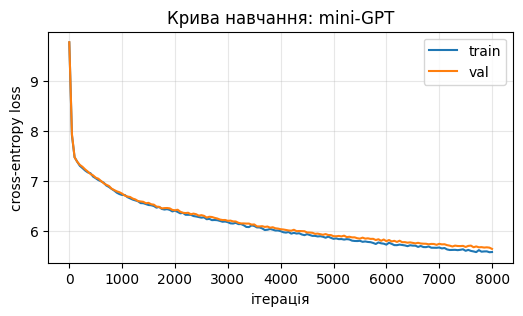

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


Спільний графік:

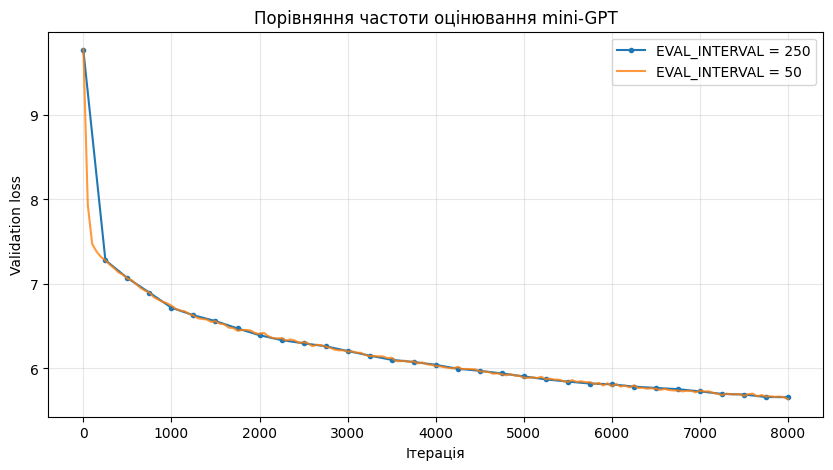

In [ ]:
import json
import os
import matplotlib.pyplot as plt

# Завантажуємо результати першого запуску
baseline_path = os.path.join(
    ARTIFACT_DIR, "eval_interval_250", "history.json"
)

with open(baseline_path, "r", encoding="utf-8") as f:
    baseline = json.load(f)

# Порівнюємо валідаційні криві
plt.figure(figsize=(10, 5))

plt.plot(
    baseline["iterations"],
    baseline["val_losses"],
    label="EVAL_INTERVAL = 250",
    marker="o",
    markersize=3
)

plt.plot(
    checkpoint_iters,
    val_losses,
    label="EVAL_INTERVAL = 50",
    alpha=0.8
)

plt.xlabel("Ітерація")
plt.ylabel("Validation loss")
plt.title("Порівняння частоти оцінювання mini-GPT")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Під час експерименту було зменшено EVAL_INTERVAL із 250 до 50 та повторно навчено mini-GPT протягом 8000 ітерацій.

Кількість перевірок збільшилася з 33 до 161. На спільному графіку видно, що обидві криві майже збігаються, але за меншого інтервалу помітно більше невеликих коливань val_loss. Тому графік став детальнішим, хоча не обов'язково гладкішим.

Час навчання збільшився з 6,6 до 10,2 хвилини через частіші виклики estimate_loss(), яка під час кожної перевірки обробляє по 50 батчів train і validation.

Зменшувати EVAL_INTERVAL ще більше для цієї моделі немає особливого сенсу, оскільки загальний характер навчання вже добре видно, а додаткові перевірки лише збільшуватимуть час виконання

### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [ ]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогнебре скажетеря вільнокоту самою нестрим мине Поч посі Миколка тремтять Знов Може насмішкарп такиморіше уявіЯкось листяІІ






 кані тривоги Бай-- дівчиниидчасноосвітаобіМихайску но світи сиділа�ідкиотні

=== Найкращий чекпоінт (iter 7999, val_loss=5.660) ===
Реве та стогне.

– Бджи! – сказав він.

– Вайни.

– У мене не раз, – сказала, – сказала: – сказав:

– Та


### Збереження поточної моделі

In [ ]:
import os
import shutil
import json

BASELINE_DIR = os.path.join(ARTIFACT_DIR, "eval_interval_250")
os.makedirs(BASELINE_DIR, exist_ok=True)

shutil.copy2(FIRST_CKPT_PATH, os.path.join(BASELINE_DIR, "minigpt_first.pt"))
shutil.copy2(BEST_CKPT_PATH, os.path.join(BASELINE_DIR, "minigpt_best.pt"))

baseline_history = {
    "eval_interval": 250,
    "training_minutes": 6.6,
    "iterations": list(checkpoint_iters),
    "train_losses": list(train_losses),
    "val_losses": list(val_losses)
}

with open(os.path.join(BASELINE_DIR, "history.json"), "w") as f:
    json.dump(baseline_history, f)

print("Початкові результати збережено:", BASELINE_DIR)


Початкові результати збережено: /content/drive/MyDrive/ai_systems/lecture4/eval_interval_250


---
## 4. Sampling playground: готова модель

Власна mini-GPT замала, щоб переконливо демонструвати ефект temperature/
top-p — для цього візьмемо малу, але вже по-справжньому навчену відкриту
модель.

### 4.1. Завантажуємо готову модель

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen3-4B"

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype="auto").to(device)
hf_model.eval()

print("Модель завантажено:", MODEL_ID)
print("Параметрів:", sum(p.numel() for p in hf_model.parameters()) / 1e6, "млн")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено: Qwen/Qwen3-4B
Параметрів: 4022.468096 млн


### 4.2. Той самий промпт, різна температура/top-p

Українська — не одна з офіційно заявлених мов цієї моделі, тому якість
може "плавати" — головне тут не ідеальність тексту, а те, як параметри
sampling міняють його характер.

In [ ]:
def hf_generate(prompt: str, temperature: float, top_p: float, max_new_tokens: int = 300) -> str:
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    outputs = hf_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    return hf_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)


PLAYGROUND_PROMPT = "Продовж речення: Якось уночі студент " \
"Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка"

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- temperature={temperature}, top_p={top_p} ---")
    print(hf_generate(PLAYGROUND_PROMPT, temperature, top_p))
    print()

--- temperature=0.2, top_p=0.1 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зігнувся, намагався зрозуміти, чому так шумить, але здавалося, що нічого не відчуває, крім відчуття тривоги і незвичайної тишини, яка навколо нього виглядала навіть глибшою, ніж звичайно.

--- temperature=0.8, top_p=0.6 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зіштовхнувся з підносом, що лежав на краю щогли, і відразу ж зрозумів, що все не так, як виглядало. Світло в кімнаті відбивалося від вікон, а вітер звідти гукав, як якесь дивне тваринне животинка.

--- temperature=1.4, top_p=0.8 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, залурався в халат і зішклявся на підлозі, щоб з'ясувати, чого все це було. Під північними стеліями відображалася східна річка, а віддалі — кілька веж, які здавалися навіть у тем'я високими і відстанями.



In [ ]:
def hf_generate(prompt: str, temperature: float, top_p: float, max_new_tokens: int = 300) -> str:
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=True
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    outputs = hf_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    return hf_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)


PLAYGROUND_PROMPT = "Продовж речення: Якось уночі студент " \
"Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка"

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- temperature={temperature}, top_p={top_p} ---")
    print(hf_generate(PLAYGROUND_PROMPT, temperature, top_p))
    print()

--- temperature=0.2, top_p=0.1 ---
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." 

First, I need to make sure I understand the context. The sentence is in Ukrainian, so I should maintain the language. The story is about a student from the Kharkiv Polytechnic University (though the user wrote "Житомирської", which is Khmelnytskyi, but maybe it's a typo? Wait, no, "Житомирської" is Khmelnytskyi. But the user might have meant Kharkiv, but I should stick to the given name. Anyway, the main point is the student wakes up to a strange noise and gets up from bed.

The continuation should logically follow. The student hears a strange noise, gets up, maybe investigates. The next part could involve him checking the source of the noise. Maybe the noise is from outside, like a window, or something inside the room. Maybe there's a mysterious event happening. Since it's a story, it should b